# Random forests for heart disease prediction

This notebook walks through building a random forest in R with the `randomForest` package. The steps are:

1. Load and clean the data
2. Impute missing values with `rfImpute()`
3. Fit a random forest and read its OOB (out-of-bag) error
4. Check whether the forest has enough trees
5. Tune `mtry`
6. Predict on new patients
7. Visualize sample relationships with an MDS plot of the proximity matrix

The data is the Cleveland heart disease data set from the UCI Machine Learning Repository: http://archive.ics.uci.edu/ml/datasets/Heart+Disease

----

## Setup

In [1]:
# load-packages
library(randomForest)

randomForest 4.7-1.2
Type rfNews() to see new features/changes/bug fixes.


The CSV has no header row, so we read it with `header = FALSE`. The file `processed_cleveland_data.csv` is expected to be in the same folder as this notebook.

In [2]:
# load-data
data <- read.csv("processed_cleveland_data.csv", header = FALSE)

## Prepare the data

We need to reformat the data so that it is:

1. Easy to use (nice column names)
2. Interpreted correctly by `randomForest()` (categorical columns stored as factors)

### Add column names

Right now we have data but no column names.

In [3]:
# preview-raw-data
head(data)

  V1 V2 V3  V4  V5 V6 V7  V8 V9 V10 V11 V12 V13 V14
1 63  1  1 145 233  1  2 150  0 2.3   3 0.0 6.0   0
2 67  1  4 160 286  0  2 108  1 1.5   2 3.0 3.0   2
3 67  1  4 120 229  0  2 129  1 2.6   2 2.0 7.0   1
4 37  1  3 130 250  0  0 187  0 3.5   3 0.0 3.0   0
5 41  0  2 130 204  0  2 172  0 1.4   1 0.0 3.0   0
6 56  1  2 120 236  0  0 178  0 0.8   1 0.0 3.0   0

In [4]:
# name-columns
colnames(data) <- c(
  "age",
  "sex", # 0 = female, 1 = male
  "cp", # chest pain
  # 1 = typical angina,
  # 2 = atypical angina,
  # 3 = non-anginal pain,
  # 4 = asymptomatic
  "trestbps", # resting blood pressure (in mm Hg)
  "chol", # serum cholestoral in mg/dl
  "fbs", # fasting blood sugar if less than 120 mg/dl, 1 = TRUE, 0 = FALSE
  "restecg", # resting electrocardiographic results
  # 1 = normal
  # 2 = having ST-T wave abnormality
  # 3 = showing probable or definite left ventricular hypertrophy
  "thalach", # maximum heart rate achieved
  "exang", # exercise induced angina, 1 = yes, 0 = no
  "oldpeak", # ST depression induced by exercise relative to rest
  "slope", # the slope of the peak exercise ST segment
  # 1 = upsloping
  # 2 = flat
  # 3 = downsloping
  "ca", # number of major vessels (0-3) colored by fluoroscopy
  "thal", # this is short of thalium heart scan
  # 3 = normal (no cold spots)
  # 6 = fixed defect (cold spots during rest and exercise)
  # 7 = reversible defect (when cold spots only appear during exercise)
  "hd" # (the predicted attribute) - diagnosis of heart disease
  # 0 if less than or equal to 50% diameter narrowing
  # 1 if greater than 50% diameter narrowing
)

head(data) # now we have data and column names

  age sex cp trestbps chol fbs restecg thalach exang oldpeak slope  ca thal hd
1  63   1  1      145  233   1       2     150     0     2.3     3 0.0  6.0  0
2  67   1  4      160  286   0       2     108     1     1.5     2 3.0  3.0  2
3  67   1  4      120  229   0       2     129     1     2.6     2 2.0  7.0  1
4  37   1  3      130  250   0       0     187     0     3.5     3 0.0  3.0  0
5  41   0  2      130  204   0       2     172     0     1.4     1 0.0  3.0  0
6  56   1  2      120  236   0       0     178     0     0.8     1 0.0  3.0  0

### Inspect column types

`str()` shows which columns need to be converted to factors. It also reveals missing values, which are coded as `"?"` in this data set.

In [5]:
# inspect-structure
str(data)

'data.frame':	303 obs. of  14 variables:
 $ age     : num  63 67 67 37 41 56 62 57 63 53 ...
 $ sex     : num  1 1 1 1 0 1 0 0 1 1 ...
 $ cp      : num  1 4 4 3 2 2 4 4 4 4 ...
 $ trestbps: num  145 160 120 130 130 120 140 120 130 140 ...
 $ chol    : num  233 286 229 250 204 236 268 354 254 203 ...
 $ fbs     : num  1 0 0 0 0 0 0 0 0 1 ...
 $ restecg : num  2 2 2 0 2 0 2 0 2 2 ...
 $ thalach : num  150 108 129 187 172 178 160 163 147 155 ...
 $ exang   : num  0 1 1 0 0 0 0 1 0 1 ...
 $ oldpeak : num  2.3 1.5 2.6 3.5 1.4 0.8 3.6 0.6 1.4 3.1 ...
 $ slope   : num  3 2 2 3 1 1 3 1 2 3 ...
 $ ca      : chr  "0.0" "3.0" "2.0" "0.0" ...
 $ thal    : chr  "6.0" "3.0" "7.0" "3.0" ...
 $ hd      : int  0 2 1 0 0 0 3 0 2 1 ...


### Handle missing values and convert to factors

First, replace the `"?"`s with `NA`. Then convert the categorical variables to factors.

The `ca` and `thal` columns contained `"?"`, so R read them as strings. We know their values are really integers, so we convert to integer first and then to factor. This also drops `"?"` from the factor levels.

In [6]:
# clean-data
## Replace "?"s with NAs
data[data == "?"] <- NA

## Recode sex as F/M and convert to factor
data[data$sex == 0, ]$sex <- "F"
data[data$sex == 1, ]$sex <- "M"
data$sex <- as.factor(data$sex)

## Columns that are already clean numeric codes only need as.factor()
data$cp <- as.factor(data$cp)
data$fbs <- as.factor(data$fbs)
data$restecg <- as.factor(data$restecg)
data$exang <- as.factor(data$exang)
data$slope <- as.factor(data$slope)

## "ca" and "thal" had "?"s, so convert string -> integer -> factor
data$ca <- as.integer(data$ca)
data$ca <- as.factor(data$ca)

data$thal <- as.integer(data$thal)
data$thal <- as.factor(data$thal)

## Replace 0 and 1 in the outcome with "Healthy" and "Unhealthy"
data$hd <- ifelse(test = data$hd == 0, yes = "Healthy", no = "Unhealthy")
data$hd <- as.factor(data$hd)

Check the result: the correct columns should now be factors, and `"?"` should no longer appear in the levels of `ca` and `thal`.

In [7]:
# verify-cleaned-data
str(data)

'data.frame':	303 obs. of  14 variables:
 $ age     : num  63 67 67 37 41 56 62 57 63 53 ...
 $ sex     : Factor w/ 2 levels "F","M": 2 2 2 2 1 2 1 1 2 2 ...
 $ cp      : Factor w/ 4 levels "1","2","3","4": 1 4 4 3 2 2 4 4 4 4 ...
 $ trestbps: num  145 160 120 130 130 120 140 120 130 140 ...
 $ chol    : num  233 286 229 250 204 236 268 354 254 203 ...
 $ fbs     : Factor w/ 2 levels "0","1": 2 1 1 1 1 1 1 1 1 2 ...
 $ restecg : Factor w/ 3 levels "0","1","2": 3 3 3 1 3 1 3 1 3 3 ...
 $ thalach : num  150 108 129 187 172 178 160 163 147 155 ...
 $ exang   : Factor w/ 2 levels "0","1": 1 2 2 1 1 1 1 2 1 2 ...
 $ oldpeak : num  2.3 1.5 2.6 3.5 1.4 0.8 3.6 0.6 1.4 3.1 ...
 $ slope   : Factor w/ 3 levels "1","2","3": 3 2 2 3 1 1 3 1 2 3 ...
 $ ca      : Factor w/ 4 levels "0","1","2","3": 1 4 3 1 1 1 3 1 2 1 ...
 $ thal    : Factor w/ 3 levels "3","6","7": 2 1 3 1 1 1 1 1 3 3 ...
 $ hd      : Factor w/ 2 levels "Healthy","Unhealthy": 1 2 2 1 1 1 2 1 2 2 ...


## Build a random forest

### A note on training and test sets

For most machine learning methods, you divide the data manually into a training set and a test set, train on the first, and evaluate on the second.

Random forests do this split for you. Each tree is built from a bootstrapped sample, so not every sample is used to build every tree. The bootstrapped data is the "training" data for that tree, and the samples left out are the "test" data. Those left-out samples are called the Out-Of-Bag (OOB) data.

### Impute missing values

`rfImpute()` fills in missing values using random forest proximities.

- `iter` is the number of iterations. Breiman suggests 4 to 6 is usually enough. With `iter = 6` on this data, the OOB error bounces around between 17% and 18%. Running 20 iterations gave values a little better and a little worse, so more iterations did not clearly help.
- You can also change the number of trees (the default is 300) and the number of variables considered at each step.

We set a seed because the algorithm is random.

In [8]:
# impute-missing-values
set.seed(42)

data.imputed <- rfImpute(hd ~ ., data = data, iter = 6)

ntree      OOB      1      2
  300:  17.49% 12.80% 23.02%
ntree      OOB      1      2
  300:  16.83% 14.02% 20.14%
ntree      OOB      1      2
  300:  17.82% 13.41% 23.02%
ntree      OOB      1      2
  300:  17.49% 14.02% 21.58%
ntree      OOB      1      2
  300:  17.16% 12.80% 22.30%
ntree      OOB      1      2
  300:  18.15% 14.63% 22.30%


### Fit the forest

`mtry` is the number of variables considered at each split. The default depends on the outcome type:

- Continuous outcome (e.g. weight or height): the number of variables divided by 3 (rounded down), or 1 if that is less than 1.
- Factor outcome (e.g. yes/no): the square root of the number of variables, rounded down.

Here `hd` is a factor and there are 13 predictors, so the default is `mtry = floor(sqrt(13)) = 3`. By default `randomForest()` builds 500 trees (`rfImpute()` builds 300).

We set `proximity = TRUE` so the model stores how often pairs of samples land in the same leaf. We use this later for the MDS plot.

In [9]:
# fit-random-forest
model <- randomForest(
  hd ~ .,
  data = data.imputed,
  proximity = TRUE
)

Printing the model gives an overview of the call, along with:

1. The OOB error rate for the forest with `ntree` trees (500 by default).
2. The confusion matrix for the forest. Rows are the true class and columns are the forest's call:

|               | Called Healthy                                  | Called Unhealthy                                  |
|---------------|-------------------------------------------------|---------------------------------------------------|
| **Healthy**   | Healthy people correctly called "healthy"       | Healthy people incorrectly called "unhealthy"     |
| **Unhealthy** | Unhealthy people incorrectly called "healthy"   | Unhealthy people correctly called "unhealthy"     |

In [10]:
# print-model
model


Call:
 randomForest(formula = hd ~ ., data = data.imputed, proximity = TRUE) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 3

        OOB estimate of  error rate: 16.83%
Confusion matrix:
          Healthy Unhealthy class.error
Healthy       142        22   0.1341463
Unhealthy      29       110   0.2086331

## Check whether the forest is big enough

Up to a point, more trees is better. You have enough trees when the OOB error stops improving. The model stores the error rate after each tree in `model$err.rate`, with columns for the overall OOB error and the error for each class. We reshape it into a long data frame for plotting.

In [11]:
# reshape-oob-error
oob.error.data <- data.frame(
  Trees = rep(1:nrow(model$err.rate), times = 3),
  Type = rep(
    c("OOB", "Healthy", "Unhealthy"),
    each = nrow(model$err.rate)
  ),
  Error = c(
    model$err.rate[, "OOB"],
    model$err.rate[, "Healthy"],
    model$err.rate[, "Unhealthy"]
  )
)

In the plot below:

- Green line: the overall OOB error rate.
- Red line: the error rate for OOB samples that are actually "Healthy".
- Blue line: the error rate for OOB samples that are actually "Unhealthy".

Look for the point where the lines flatten out. The original script concluded that 500 trees was plenty, with the error rates reaching their lowest points around 200 trees and staying flat afterwards. Confirm that against your own plot, since the results depend on the random seed.

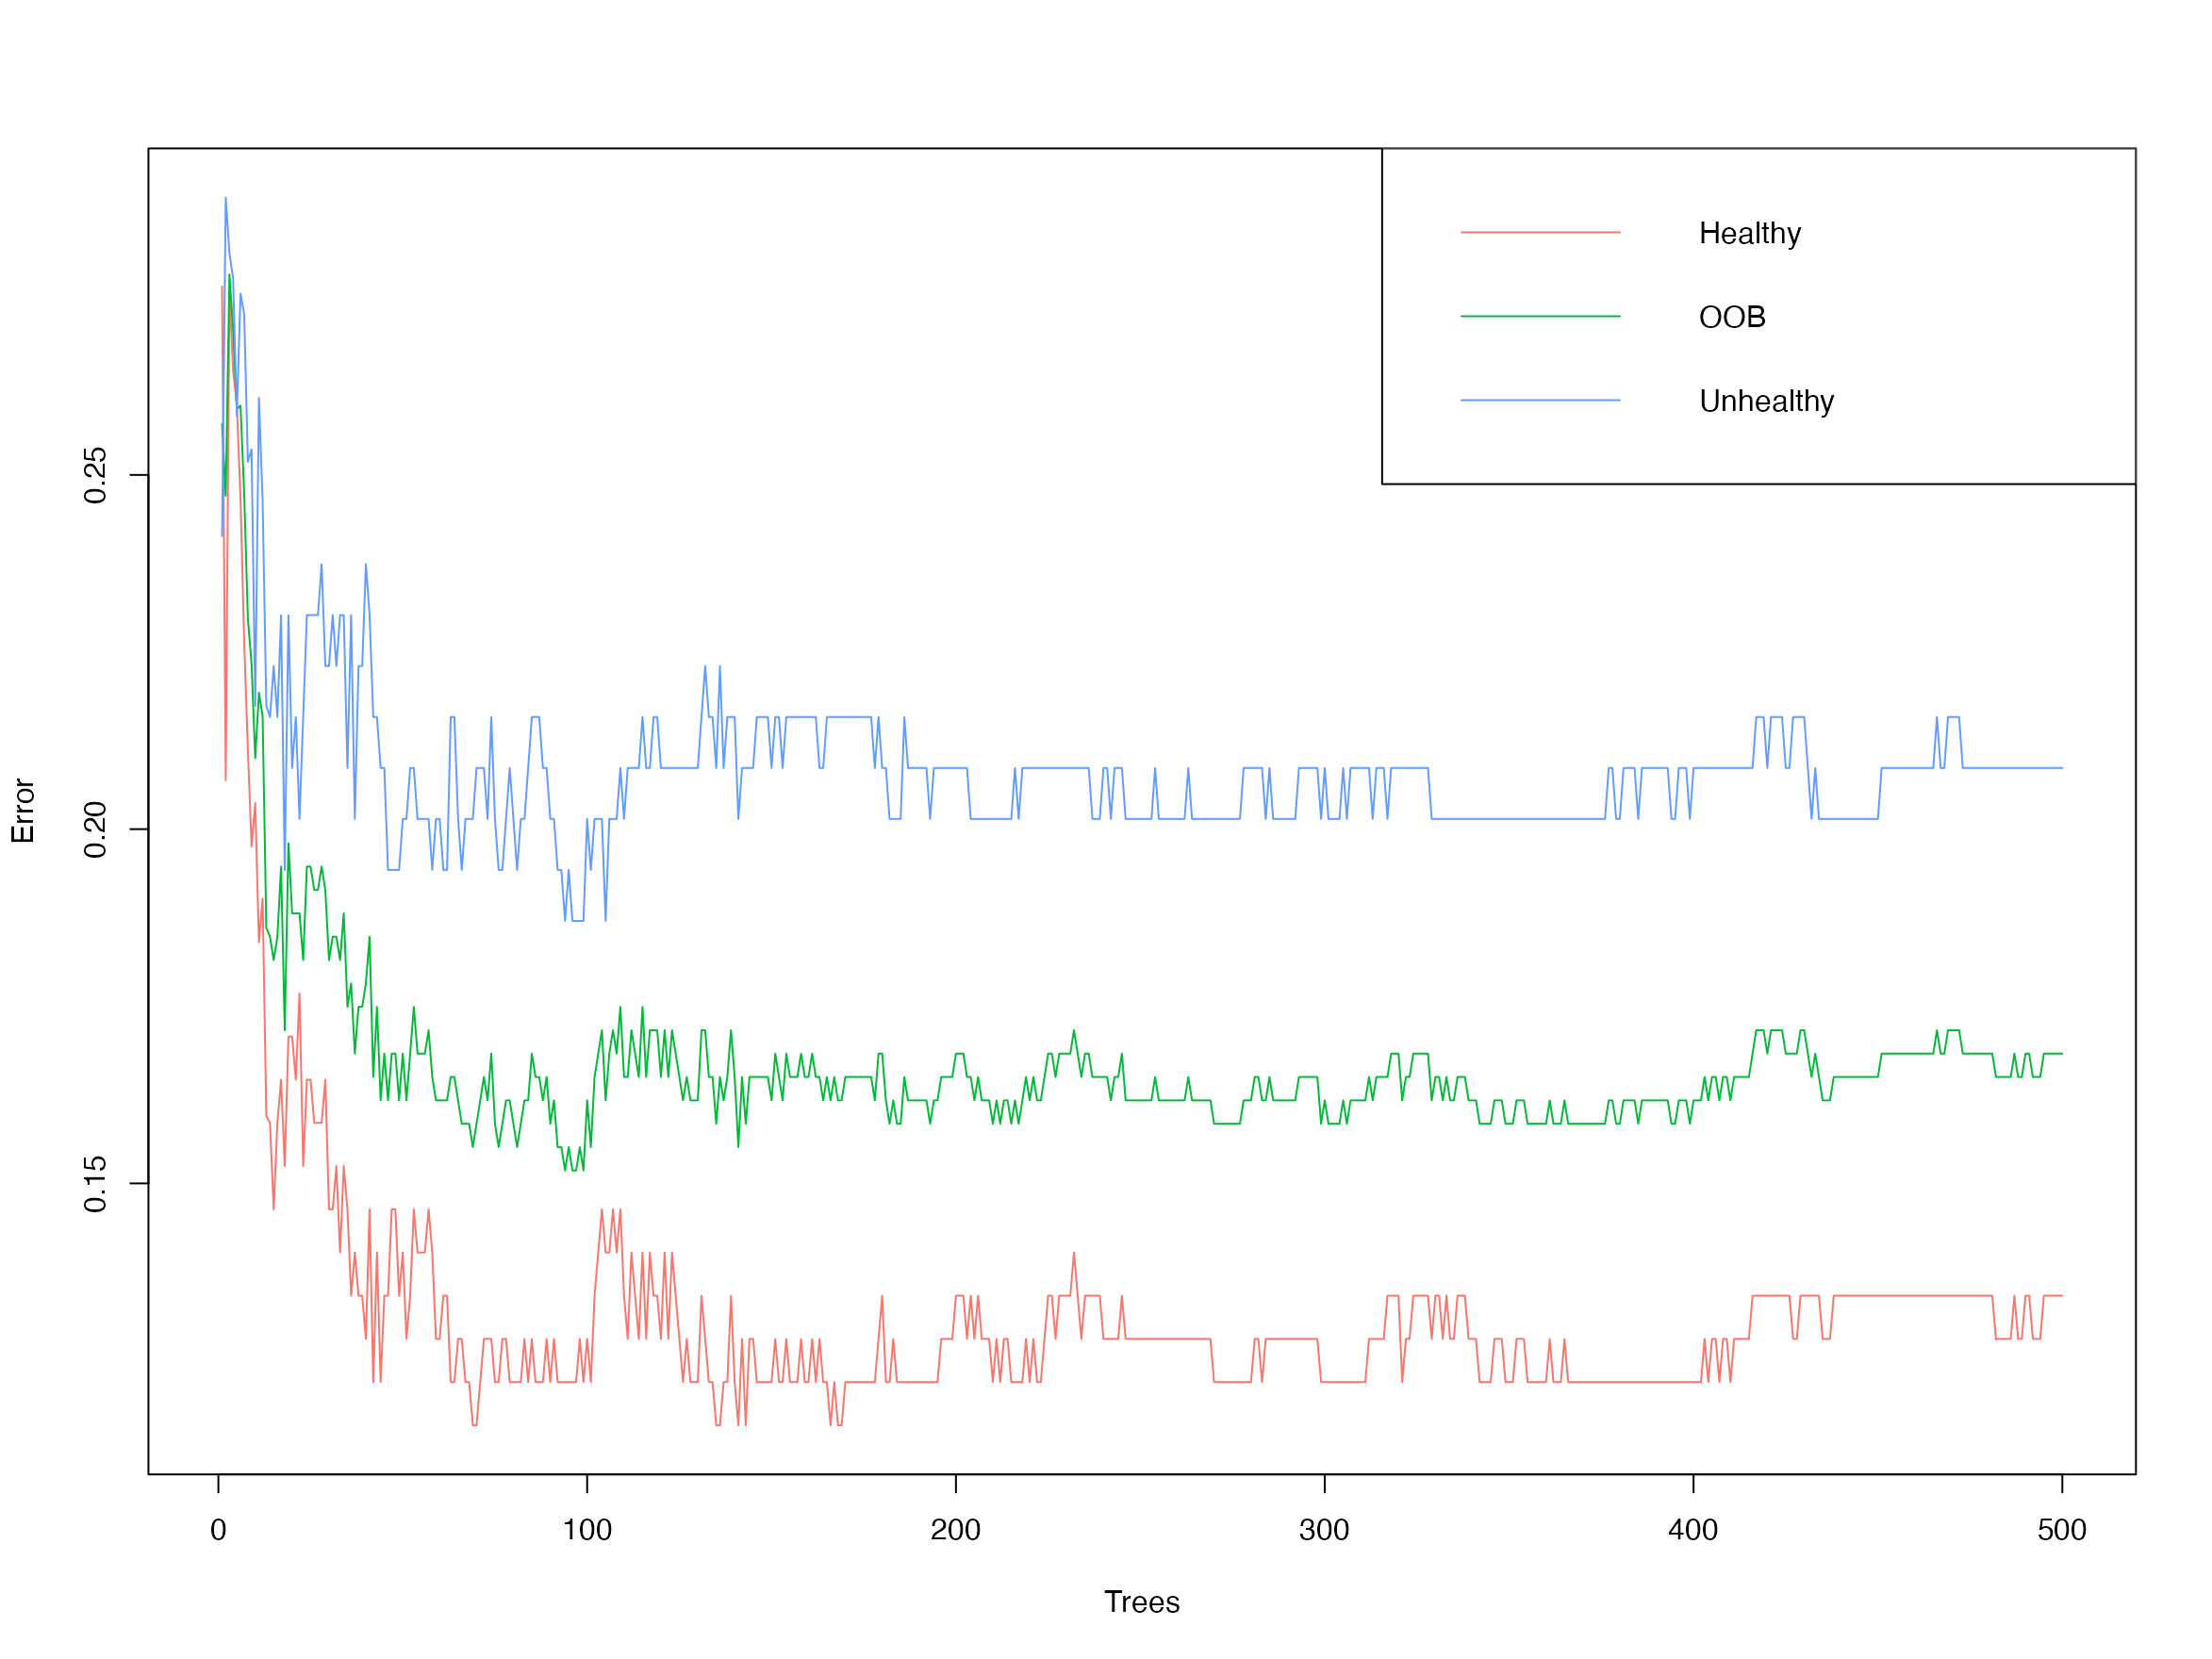

In [12]:
# plot-oob-error
oob.colors <- c(
  Healthy = "#F8766D",
  OOB = "#00BA38",
  Unhealthy = "#619CFF"
)

## Draw an empty plot to set up the axes, then add one line per error type
plot(
  Error ~ Trees,
  data = oob.error.data,
  type = "n"
)
for (type in names(oob.colors)) {
  with(
    subset(oob.error.data, Type == type),
    lines(
      Trees,
      Error,
      col = oob.colors[[type]]
    )
  )
}
legend(
  "topright",
  legend = names(oob.colors),
  col = oob.colors,
  lty = 1
)

## To save the plot as a PDF, uncomment these lines and run them around the plot code
# pdf("oob_error_rate_500_trees.pdf", width = 6, height = 6, bg = "transparent")
# dev.off()

## Tune `mtry`

To see whether a different number of variables per split gives a lower OOB error, we fit one forest for each `mtry` from 1 to 10 and record the final overall OOB error of each. The first column of `err.rate` is the overall OOB error, and the last row is the error after all trees.

Note that this loop is not seeded separately, so the exact numbers depend on the random state at this point.

In [13]:
# tune-mtry
oob.values <- vector(length = 10)
for (i in 1:10) {
  temp.model <- randomForest(
    hd ~ .,
    data = data.imputed,
    mtry = i,
    ntree = 500
  )
  oob.values[i] <- temp.model$err.rate[
    nrow(temp.model$err.rate),
    1
  ]
}
oob.values

 [1] 0.1650165 0.1782178 0.1683168 0.1848185 0.1881188 0.1815182 0.1848185 0.1881188 0.1848185 0.1881188

In [14]:
# best-mtry
## Minimum OOB error
min(oob.values)

## The mtry value(s) that achieve it
which(oob.values == min(oob.values))

[1] 1

Refit the forest using the best `mtry`, keeping the proximities for the MDS plot later. If several values tie for the minimum, `which()` returns more than one and `randomForest()` would fail or misbehave, so you may want to pick one explicitly in that case.

In [15]:
# fit-final-model
model <- randomForest(
  hd ~ .,
  data = data.imputed,
  ntree = 500,
  proximity = TRUE,
  mtry = which(oob.values == min(oob.values))
)

## Apply the model to new patients

The new data must have the same columns as the data used to fit the model (except `hd`, which is what we are predicting), and the factor columns must use the same levels. Setting `levels = levels(data.imputed$...)` takes care of that.

In [16]:
# create-new-patients
new.patients <- data.frame(
  age = c(58, 35),
  sex = factor(c("M", "F"), levels = levels(data.imputed$sex)),
  cp = factor(c("4", "3"), levels = levels(data.imputed$cp)),
  trestbps = c(140, 115),
  chol = c(250, 190),
  fbs = factor(c("0", "0"), levels = levels(data.imputed$fbs)),
  restecg = factor(c("0", "2"), levels = levels(data.imputed$restecg)),
  thalach = c(130, 175),
  exang = factor(c("1", "0"), levels = levels(data.imputed$exang)),
  oldpeak = c(1.5, 0),
  slope = factor(c("2", "1"), levels = levels(data.imputed$slope)),
  ca = factor(c("1", "0"), levels = levels(data.imputed$ca)),
  thal = factor(c("7", "3"), levels = levels(data.imputed$thal))
)

new.patients

  age sex cp trestbps chol fbs restecg thalach exang oldpeak slope ca thal
1  58   M  4      140  250   0       0     130     1     1.5     2  1    7
2  35   F  3      115  190   0       2     175     0     0.0     1  0    3

In [17]:
# name-new-patients
rownames(new.patients) <- c("patient.1", "patient.2")
new.patients

          age sex cp trestbps chol fbs restecg thalach exang oldpeak slope ca thal
patient.1  58   M  4      140  250   0       0     130     1     1.5     2  1    7
patient.2  35   F  3      115  190   0       2     175     0     0.0     1  0    3

The predicted class for each patient:

In [18]:
# predict-class
predict(model, newdata = new.patients)

patient.1 patient.2 
Unhealthy   Healthy 
Levels: Healthy Unhealthy

The proportion of trees that voted for each class:

In [19]:
# predict-probabilities
predict(model, newdata = new.patients, type = "prob")

          Healthy Unhealthy
patient.1   0.056     0.944
patient.2   0.972     0.028
attr(,"class")
[1] "matrix" "array"  "votes" 

## Visualize sample relationships with an MDS plot

A multi-dimensional scaling (MDS) plot shows how the samples relate to each other according to the forest.

1. Convert the proximity matrix into a distance matrix (`1 - proximity`).
2. Run classical MDS with `cmdscale()`.
3. Compute the percent of variation each MDS axis accounts for, to label the axes.

In [20]:
# compute-mds
distance.matrix <- as.dist(1 - model$proximity)

mds.stuff <- cmdscale(
  distance.matrix,
  eig = TRUE,
  x.ret = TRUE
)

## Percentage of variation accounted for by each MDS axis
mds.var.per <- round(
  mds.stuff$eig / sum(mds.stuff$eig) * 100,
  1
)

Collect the first two MDS axes, along with each sample's ID and health status, into a data frame, then plot each sample as its row label colored by status.

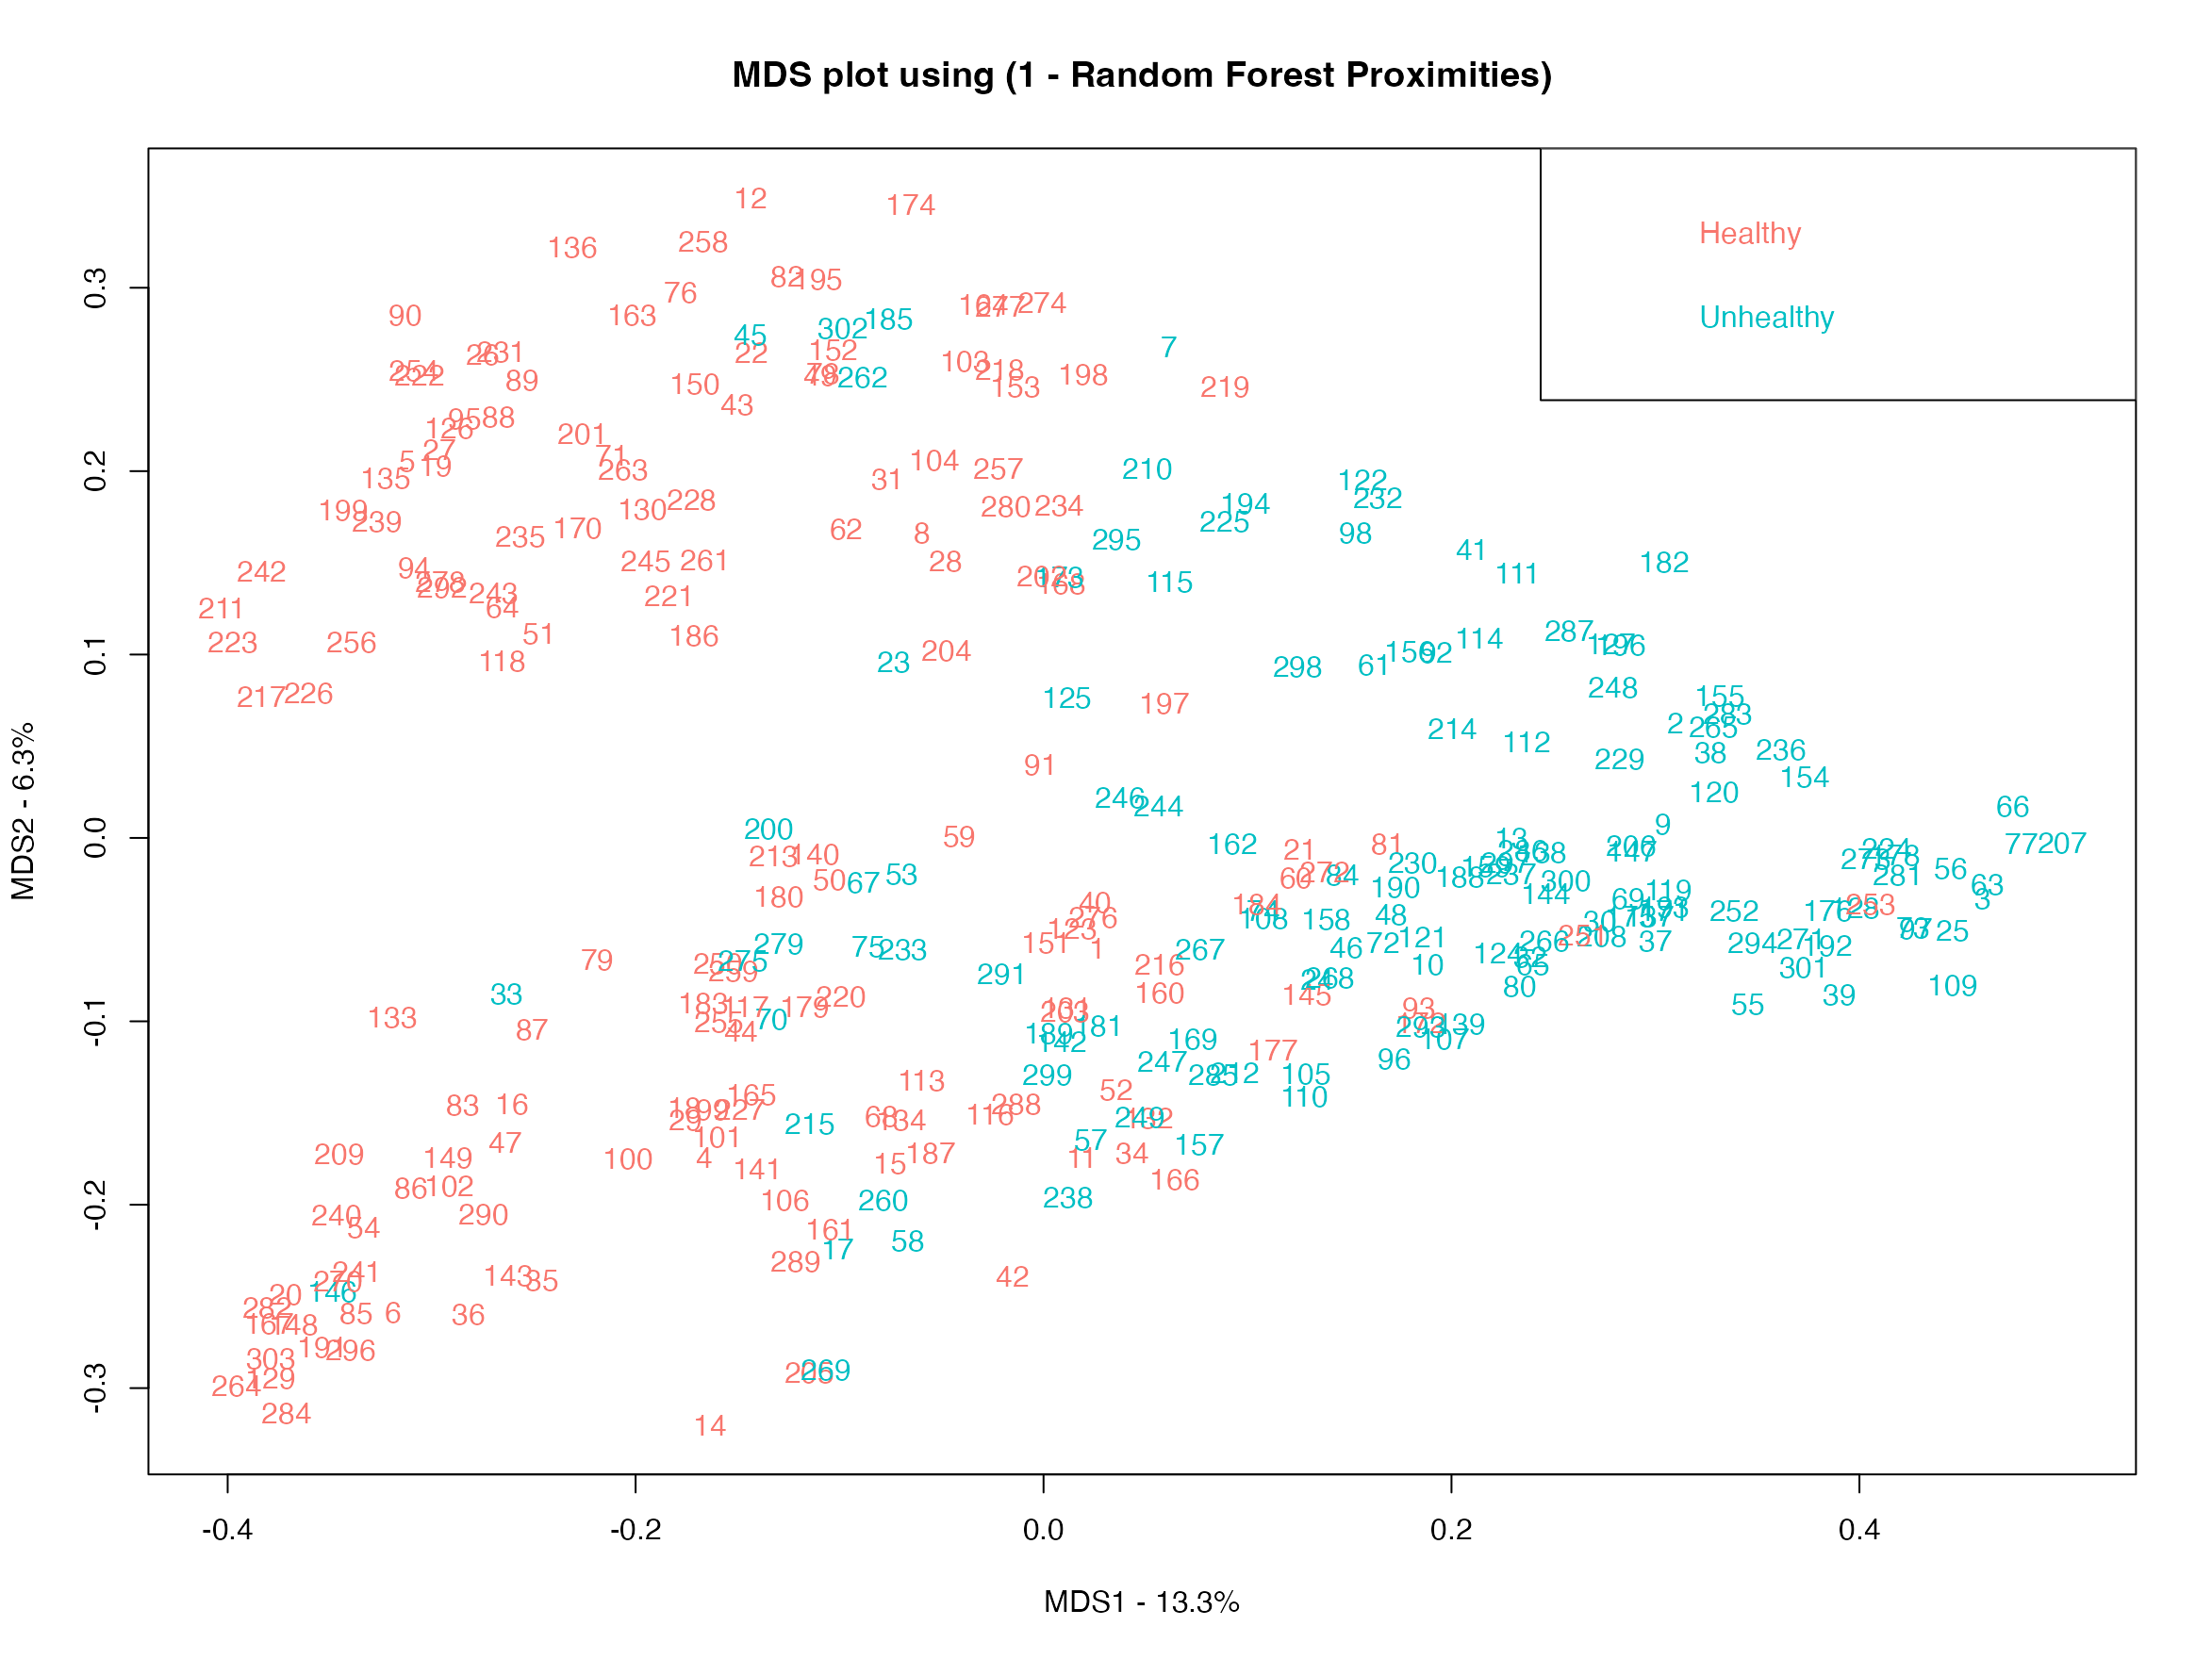

In [21]:
# plot-mds
mds.values <- mds.stuff$points
mds.data <- data.frame(
  Sample = rownames(mds.values),
  X = mds.values[, 1],
  Y = mds.values[, 2],
  Status = data.imputed$hd
)

status.colors <- c(
  Healthy = "#F8766D",
  Unhealthy = "#00BFC4"
)

plot(
  mds.data$X,
  mds.data$Y,
  type = "n",
  xlab = paste("MDS1 - ", mds.var.per[1], "%", sep = ""),
  ylab = paste("MDS2 - ", mds.var.per[2], "%", sep = ""),
  main = "MDS plot using (1 - Random Forest Proximities)"
)
text(
  mds.data$X,
  mds.data$Y,
  labels = mds.data$Sample,
  col = status.colors[as.character(mds.data$Status)]
)
legend(
  "topright",
  legend = names(status.colors),
  text.col = status.colors
)

## To save the plot as a PDF, uncomment these lines and run them around the plot code
# pdf("random_forest_for_clustering.pdf", width = 6, height = 6, bg = "transparent")
# dev.off()